# 04 - Revenue Analysis 💰

**Goal:** understand where the hotel's revenue comes from.

**Feature to build:** `revenue = adr * total_stay`

**Questions to answer:**
- What is total revenue by hotel type?
- How does revenue trend by month?
- Which countries generate the most revenue?
- Which distribution channel generates the most revenue?

In [1]:
import sys
sys.path.append('..')

import pandas as pd

from src.config import CLEAN_DATA_PATH
from src.feature_engineering import add_stay_features, add_revenue
from src.analysis import revenue_by_hotel, monthly_revenue_trend, revenue_by_country, revenue_by_channel
from src.visualization import plot_revenue_by, plot_monthly_revenue_trend

df = pd.read_csv(CLEAN_DATA_PATH)
df = add_stay_features(df)
df = add_revenue(df)
df[['total_stay', 'revenue']].describe()

,total_stay,revenue
count,87139.000000,87139.000000
mean,3.627836,393.713268
std,2.743184,366.180694
min,0.000000,0.000000
25%,2.000000,153.000000
50%,3.000000,299.200000
75%,5.000000,502.810000
max,69.000000,7590.000000


## Revenue by hotel type

hotel
City Hotel      18748439.98
Resort Hotel    15559340.50
Name: revenue, dtype: float64

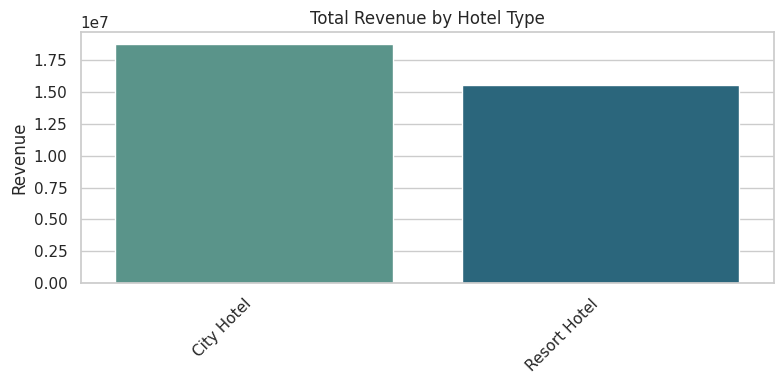

In [2]:
rev_by_hotel = revenue_by_hotel(df)
plot_revenue_by(rev_by_hotel, 'Total Revenue by Hotel Type', 'Revenue', '15_revenue_by_hotel.png')
rev_by_hotel

## Monthly revenue trend

arrival_date_month
January      1079209.86
February     1472725.43
March        2042972.89
April        2786002.29
May          3119727.78
June         3495592.65
July         5830753.62
August       7144151.87
September    2687110.85
October      2032649.25
November     1217518.38
December     1399365.61
Name: revenue, dtype: float64

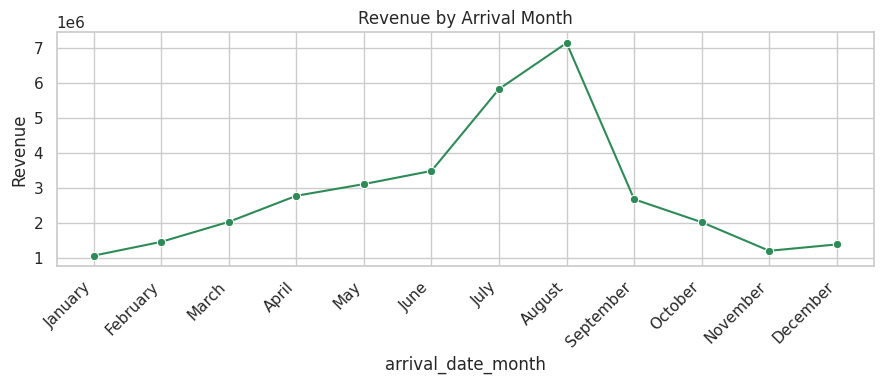

In [3]:
monthly_rev = monthly_revenue_trend(df)
plot_monthly_revenue_trend(monthly_rev)
monthly_rev

## Revenue by country (top 10)

country
PRT    9105409.42
GBR    4713908.01
FRA    3594052.87
ESP    2936754.83
DEU    2113113.24
IRL    1536605.05
ITA    1211384.46
BEL     881121.63
BRA     795122.03
NLD     731798.56
Name: revenue, dtype: float64

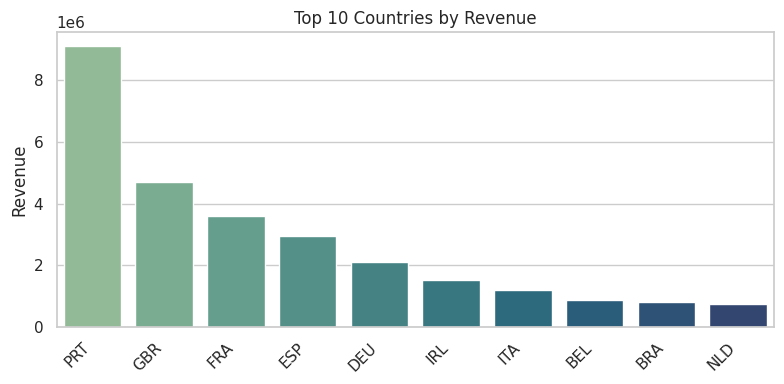

In [4]:
rev_by_country = revenue_by_country(df, top_n=10)
plot_revenue_by(rev_by_country, 'Top 10 Countries by Revenue', 'Revenue', '16_revenue_by_country.png')
rev_by_country

## Revenue by distribution channel

**Question:** which channel generates the most revenue?

distribution_channel
TA/TO        28486499.71
Direct        4942864.13
Corporate      833616.82
GDS             43628.82
Undefined        1171.00
Name: revenue, dtype: float64

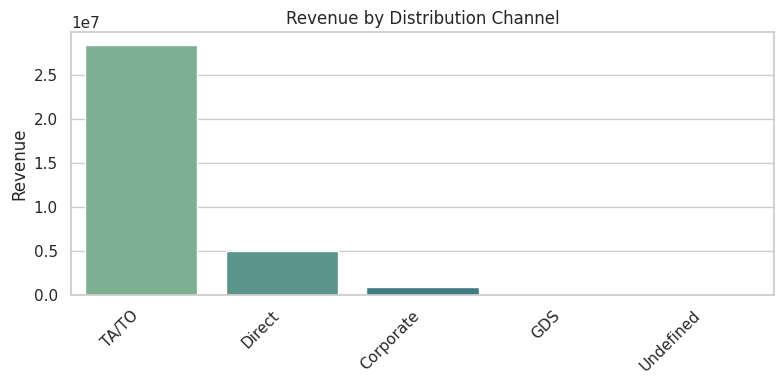

In [5]:
rev_by_channel = revenue_by_channel(df)
plot_revenue_by(rev_by_channel, 'Revenue by Distribution Channel', 'Revenue', '17_revenue_by_channel.png')
rev_by_channel

## Key insight

In [6]:
top_channel = rev_by_channel.idxmax()
top_country = rev_by_country.idxmax()
total_revenue = df['revenue'].sum()
print(f"- Total revenue across the cleaned dataset: {total_revenue:,.0f}.")
print(f"- '{top_channel}' is the single largest revenue channel ({rev_by_channel.max():,.0f}).")
print(f"- {top_country} is the top revenue-generating country ({rev_by_country.max():,.0f}).")

- Total revenue across the cleaned dataset: 34,307,780.
- 'TA/TO' is the single largest revenue channel (28,486,500).
- PRT is the top revenue-generating country (9,105,409).
